In [1]:
#!pip install contractions

In [2]:
import pandas as pd
import re
import nltk
import contractions
import string
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet
from nltk.corpus import stopwords

In [3]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [ ]:
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('stopwords')
nltk.download('wordnet')

In [4]:
review_df = pd.read_csv("../data/IMDB Dataset.csv")

review_df.shape

(50000, 2)

In [5]:
review_df.drop_duplicates(inplace=True)

review_df.shape

(49582, 2)

In [6]:
review_df["clean_review"] = review_df["review"]

In [7]:
def remove_html(text):
    return re.sub(r"<.*?>", " ", text)

review_df["clean_review"] = review_df["clean_review"].apply(remove_html)

In [8]:
print("Before:\n")
print(review_df["review"].iloc[0])

print("\n" + "="*80 + "\n")

print("After:\n")
print(review_df["clean_review"].iloc[0])

Before:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due t

In [9]:
review_df["clean_review"] = review_df["clean_review"].str.lower()

In [10]:
print("Before:\n")
print(review_df["review"].iloc[0])

print("\n" + "="*80 + "\n")

print("After:\n")
print(review_df["clean_review"].iloc[0])

Before:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due t

In [11]:
def expand_contractions(text):
    return contractions.fix(text)

In [12]:
review_df["clean_review"] = review_df["clean_review"].apply(expand_contractions)

In [13]:
print("Before:\n")
print(review_df["review"].iloc[0])

print("\n" + "="*80 + "\n")

print("After:\n")
print(review_df["clean_review"].iloc[0])

Before:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due t

In [14]:
print(string.punctuation)

!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [15]:
def remove_punctuation(text):
    return re.sub(r"[^\w\s]", " ", text)

In [16]:
review_df["clean_review"] = review_df["clean_review"].apply(remove_punctuation)

In [17]:
print("Before:\n")
print(review_df["review"].iloc[0])

print("\n" + "=" * 80 + "\n")

print("After:\n")
print(review_df["clean_review"].iloc[0])

Before:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due t

In [18]:
def remove_numbers(text):
    return re.sub(r"\d+", "", text)

In [19]:
review_df["clean_review"] = review_df["clean_review"].apply(remove_numbers)

In [20]:
print("Before:\n")
print(review_df["review"].iloc[87])

print("\n" + "=" * 80 + "\n")

print("After:\n")
print(review_df["clean_review"].iloc[87])

Before:

Oh noes one of these attack of the Japanese ghost girl movies... i don't even remember how many i've seen. maybe it sells... but not to me. not scary at all. the japanese horror movies are have been very similar since the first one of these... also the pulling of the kid. i have seen that pulled under scene so many times in so many horror movies. cellphone scene is also nothing new... the dramaticness of the guy getting hit by a train kinda sucked... i mean it lacked all dramaticness... OK this is for kids 14-16 who listen to japanese rock and think they are so unique... we'll let me tell you. there's a million of you =D this is one of them. 3/10 i've seen worse but you won't be missing anything by NOT seeing this!


After:

oh noes one of these attack of the japanese ghost girl movies    i do not even remember how many i have seen  maybe it sells    but not to me  not scary at all  the japanese horror movies are have been very similar since the first one of these    also the 

In [21]:
def remove_extra_spaces(text):
    return re.sub(r"\s+", " ", text).strip()

In [22]:
review_df["clean_review"] = review_df["clean_review"].apply(remove_extra_spaces)

In [23]:
print("Before:\n")
print(review_df["review"].iloc[87])

print("\n" + "=" * 80 + "\n")

print("After:\n")
print(review_df["clean_review"].iloc[87])

Before:

Oh noes one of these attack of the Japanese ghost girl movies... i don't even remember how many i've seen. maybe it sells... but not to me. not scary at all. the japanese horror movies are have been very similar since the first one of these... also the pulling of the kid. i have seen that pulled under scene so many times in so many horror movies. cellphone scene is also nothing new... the dramaticness of the guy getting hit by a train kinda sucked... i mean it lacked all dramaticness... OK this is for kids 14-16 who listen to japanese rock and think they are so unique... we'll let me tell you. there's a million of you =D this is one of them. 3/10 i've seen worse but you won't be missing anything by NOT seeing this!


After:

oh noes one of these attack of the japanese ghost girl movies i do not even remember how many i have seen maybe it sells but not to me not scary at all the japanese horror movies are have been very similar since the first one of these also the pulling of t

In [24]:
def tokenize_text(text):
    return word_tokenize(text)

In [25]:
review_df["tokens"] = review_df["clean_review"].apply(tokenize_text)

In [26]:
print("Before:\n")
print(review_df["clean_review"].iloc[87])

print("\n" + "=" * 80 + "\n")

print("After:\n")
print(review_df["tokens"].iloc[87])

Before:

oh noes one of these attack of the japanese ghost girl movies i do not even remember how many i have seen maybe it sells but not to me not scary at all the japanese horror movies are have been very similar since the first one of these also the pulling of the kid i have seen that pulled under scene so many times in so many horror movies cellphone scene is also nothing new the dramaticness of the guy getting hit by a train kind of sucked i mean it lacked all dramaticness ok this is for kids who listen to japanese rock and think they are so unique we will let me tell you there is a million of you d this is one of them i have seen worse but you will not be missing anything by not seeing this


After:

['oh', 'noes', 'one', 'of', 'these', 'attack', 'of', 'the', 'japanese', 'ghost', 'girl', 'movies', 'i', 'do', 'not', 'even', 'remember', 'how', 'many', 'i', 'have', 'seen', 'maybe', 'it', 'sells', 'but', 'not', 'to', 'me', 'not', 'scary', 'at', 'all', 'the', 'japanese', 'horror', 'mo

In [27]:
lemmatizer = WordNetLemmatizer()

In [28]:
def get_wordnet_pos(tag):

    if tag.startswith("J"):
        return wordnet.ADJ

    elif tag.startswith("V"):
        return wordnet.VERB

    elif tag.startswith("N"):
        return wordnet.NOUN

    elif tag.startswith("R"):
        return wordnet.ADV

    else:
        return wordnet.NOUN

In [29]:
pos_tag(review_df["tokens"].iloc[87])

[('oh', 'UH'),
 ('noes', 'VBZ'),
 ('one', 'CD'),
 ('of', 'IN'),
 ('these', 'DT'),
 ('attack', 'NN'),
 ('of', 'IN'),
 ('the', 'DT'),
 ('japanese', 'JJ'),
 ('ghost', 'NN'),
 ('girl', 'JJ'),
 ('movies', 'NNS'),
 ('i', 'VBP'),
 ('do', 'VBP'),
 ('not', 'RB'),
 ('even', 'RB'),
 ('remember', 'VB'),
 ('how', 'WRB'),
 ('many', 'JJ'),
 ('i', 'NNS'),
 ('have', 'VBP'),
 ('seen', 'VBN'),
 ('maybe', 'RB'),
 ('it', 'PRP'),
 ('sells', 'VBZ'),
 ('but', 'CC'),
 ('not', 'RB'),
 ('to', 'TO'),
 ('me', 'PRP'),
 ('not', 'RB'),
 ('scary', 'JJ'),
 ('at', 'IN'),
 ('all', 'PDT'),
 ('the', 'DT'),
 ('japanese', 'JJ'),
 ('horror', 'NN'),
 ('movies', 'NNS'),
 ('are', 'VBP'),
 ('have', 'VBP'),
 ('been', 'VBN'),
 ('very', 'RB'),
 ('similar', 'JJ'),
 ('since', 'IN'),
 ('the', 'DT'),
 ('first', 'JJ'),
 ('one', 'CD'),
 ('of', 'IN'),
 ('these', 'DT'),
 ('also', 'RB'),
 ('the', 'DT'),
 ('pulling', 'NN'),
 ('of', 'IN'),
 ('the', 'DT'),
 ('kid', 'NN'),
 ('i', 'NN'),
 ('have', 'VBP'),
 ('seen', 'VBN'),
 ('that', 'IN'),
 ('pul

In [30]:
def lemmatize_text(tokens):
    pos_tags = pos_tag(tokens)

    lemmatized = []

    for word, tag in pos_tags:
        pos = get_wordnet_pos(tag)
        lemma = lemmatizer.lemmatize(word, pos)
        lemmatized.append(lemma)

    return lemmatized

In [31]:
review_df["lemmatized_tokens"] = review_df["tokens"].apply(lemmatize_text)

In [32]:
stop_words = set(stopwords.words("english")) - {
    "no",
    "not",
    "nor",
    "neither",
    "never",
    "cannot"
}

In [33]:
def remove_stopwords(tokens):
    return [word for word in tokens if word not in stop_words]

In [34]:
review_df["final_tokens"] = review_df["lemmatized_tokens"].apply(remove_stopwords)

In [35]:
print("Before:\n")
print(review_df["lemmatized_tokens"].iloc[8])

print("\n" + "="*80 + "\n")

print("After:\n")
print(review_df["final_tokens"].iloc[8])

Before:

['encourage', 'by', 'the', 'positive', 'comment', 'about', 'this', 'film', 'on', 'here', 'i', 'be', 'look', 'forward', 'to', 'watch', 'this', 'film', 'bad', 'mistake', 'i', 'have', 'see', 'film', 'and', 'this', 'be', 'truly', 'one', 'of', 'the', 'bad', 'of', 'them', 'it', 'be', 'awful', 'in', 'almost', 'every', 'way', 'edit', 'pace', 'storyline', 'act', 'soundtrack', 'the', 'film', 's', 'only', 'song', 'a', 'lame', 'country', 'tune', 'be', 'play', 'no', 'less', 'than', 'four', 'time', 'the', 'film', 'look', 'cheap', 'and', 'nasty', 'and', 'be', 'bore', 'in', 'the', 'extreme', 'rarely', 'have', 'i', 'be', 'so', 'happy', 'to', 'see', 'the', 'end', 'credit', 'of', 'a', 'film', 'the', 'only', 'thing', 'that', 'prevent', 'me', 'give', 'this', 'a', 'score', 'be', 'harvey', 'keitel', 'while', 'this', 'be', 'far', 'from', 'his', 'best', 'performance', 'he', 'at', 'least', 'seem', 'to', 'be', 'make', 'a', 'bit', 'of', 'an', 'effort', 'one', 'for', 'keitel', 'obsessive', 'only']


After

In [36]:
review_df["processed_review"] = review_df["final_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

In [37]:
print("Before:\n")
print(review_df["review"].iloc[8])

print("\n" + "="*80 + "\n")

print("After:\n")
print(review_df["processed_review"].iloc[8])

Before:

Encouraged by the positive comments about this film on here I was looking forward to watching this film. Bad mistake. I've seen 950+ films and this is truly one of the worst of them - it's awful in almost every way: editing, pacing, storyline, 'acting,' soundtrack (the film's only song - a lame country tune - is played no less than four times). The film looks cheap and nasty and is boring in the extreme. Rarely have I been so happy to see the end credits of a film. <br /><br />The only thing that prevents me giving this a 1-score is Harvey Keitel - while this is far from his best performance he at least seems to be making a bit of an effort. One for Keitel obsessives only.


After:

encourage positive comment film look forward watch film bad mistake see film truly one bad awful almost every way edit pace storyline act soundtrack film song lame country tune play no less four time film look cheap nasty bore extreme rarely happy see end credit film thing prevent give score harvey

In [38]:
review_df = review_df[
    ["processed_review", "sentiment"]
]

In [39]:
review_df.to_csv(
    "../data/imdb_preprocessed.csv",
    index=False
)

In [40]:
print(review_df.head())

                                    processed_review sentiment
0  one reviewer mention watch oz episode hook rig...  positive
1  wonderful little production filming technique ...  positive
2  think wonderful way spend time hot summer week...  positive
3  basically family little boy jake think zombie ...  negative
4  petter mattei love time money visually stunnin...  positive


In [41]:
print(review_df.shape)

(49582, 2)


In [42]:
print(review_df.isnull().sum())

processed_review    0
sentiment           0
dtype: int64


In [43]:
# Load the preprocessed dataset
review_df = pd.read_csv("../data/imdb_preprocessed.csv")

# Check the first few rows
review_df.head()

,processed_review,sentiment
0,one reviewer mention watch oz episode hook rig...,positive
1,wonderful little production filming technique ...,positive
2,think wonderful way spend time hot summer week...,positive
3,basically family little boy jake think zombie ...,negative
4,petter mattei love time money visually stunnin...,positive


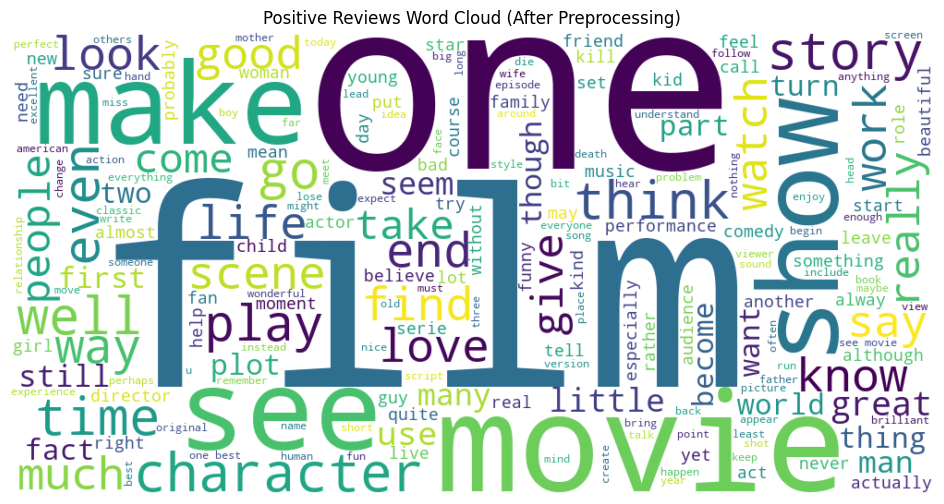

In [44]:
positive_text = " ".join(
    review_df[review_df["sentiment"] == "positive"]["processed_review"]
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Reviews Word Cloud (After Preprocessing)")
plt.show()

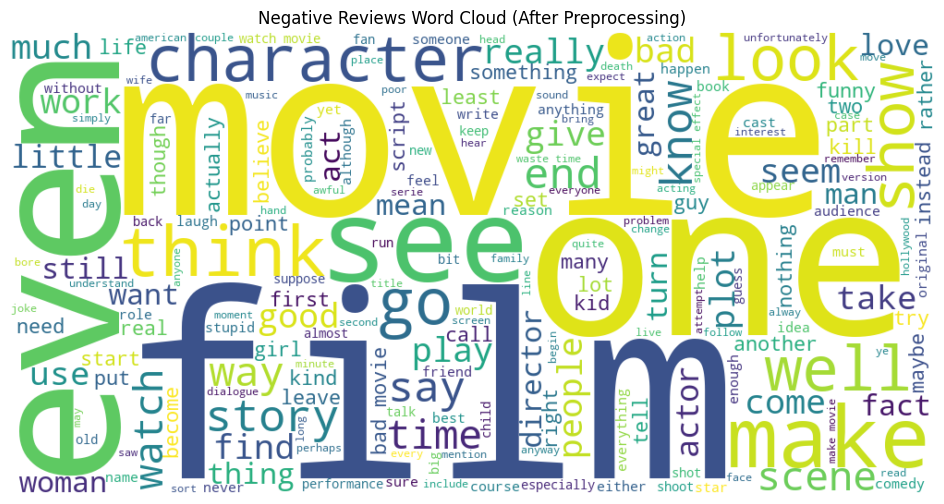

In [45]:
negative_text = " ".join(
    review_df[review_df["sentiment"] == "negative"]["processed_review"]
)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(negative_text)

plt.figure(figsize=(12,6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Reviews Word Cloud (After Preprocessing)")
plt.show()